In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from numpy import log
from scipy.stats import ks_2samp, pareto, kstest, linregress, genpareto, expon, kstest, rv_continuous, kstest, ks_2samp
import statsmodels.api as sm
from scipy.optimize import minimize_scalar
from scipy.special import gamma, gammainc, gammaincc, zeta
from Helpers import *
import pickle

In [2]:
df = pd.read_csv("data.csv")
F = df["Fatalities"].values
N = len(F)
x_min = np.min(F)

powerlaw  P val:  0.151


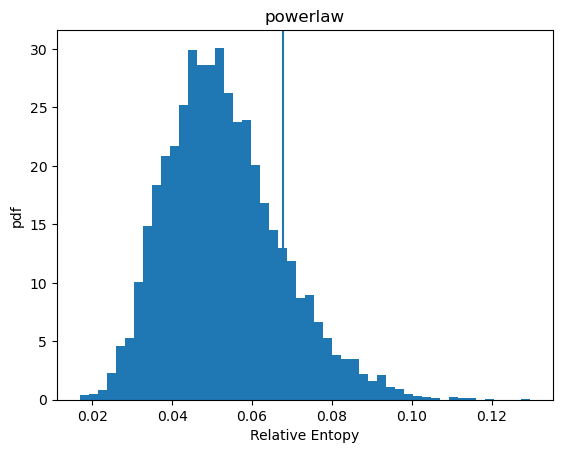

expo  P val:  0.0


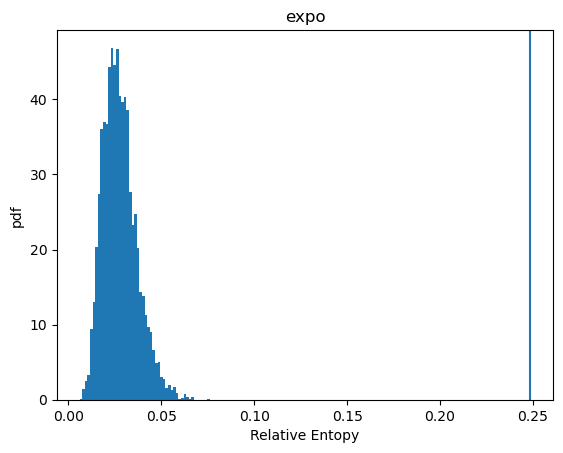

C:\Users\succa\Desktop\New Sync\Research\MS Risk\MsRisk_V9\Helpers.py:17: RuntimeWarning: invalid value encountered in divide
  return (F(x+1)-F(x))/(1-F(xmin))


lognorm  P val:  0.0106


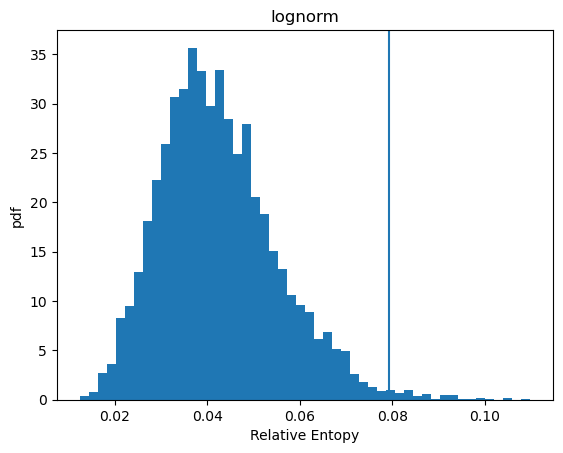

weibull  P val:  0.0


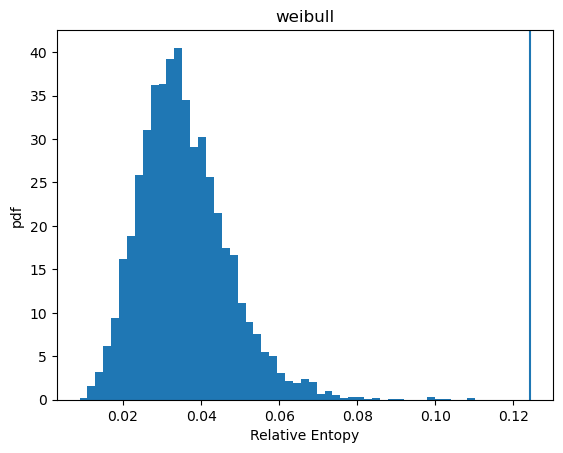

C:\Users\succa\Desktop\New Sync\Research\MS Risk\MsRisk_V9\Helpers.py:27: RuntimeWarning: invalid value encountered in divide
  return (gamma(x))/(gamma(x+a))*(a-1)*((gamma(xmin+a-1))/gamma(xmin))


yule-simon  P val:  0.0218


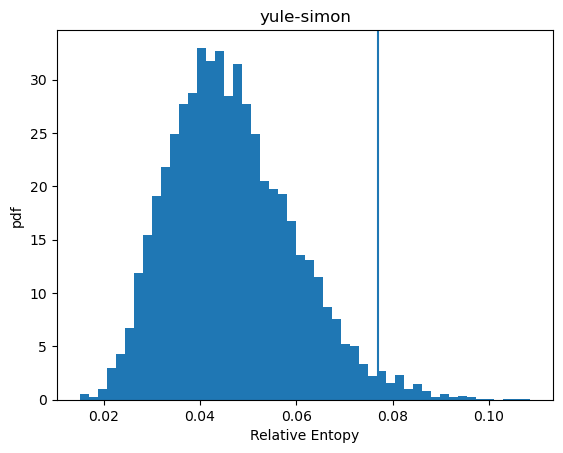

In [5]:
models = ["powerlaw", "expo", "lognorm", "weibull", "yule-simon"]
for model in models:
    RE = []
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)  
    count = 0
    while count < 5000:
        _, sample = sample_discrete(N, model, params)
        if len(sample[sample<x_min]) != 0: print(params)
        MLE_estimate = MLE(sample, model, x_min)
        if MLE_estimate[2]: 
            params_surro = np.insert(MLE_estimate[0], 0, x_min)  
            X, Px = plug_in_pdf(sample)
            RE.append(Relative_entropy(X, Px, model, params_surro))
            count += 1
    with open('Results/Surr_{}.pkl'.format(model), 'wb') as f:  # 'wb' = write binary
        pickle.dump(np.array(RE), f)
    X, Px = plug_in_pdf(F)
    Real_RE = Relative_entropy(X, Px, model, params)
    plt.hist(RE, bins = 50, density = True)
    plt.ylabel("pdf")
    plt.xlabel("Relative Entopy")
    plt.axvline(Real_RE)
    plt.title(model)
    print(model, " P val: ", np.mean(RE > Real_RE))
    plt.show()